# Exercise 2: Sinusoids and the DFT

This exercise builds intuition for the main operations behind the Discrete Fourier Transform (DFT). It has five parts:
1. Generate a real sinusoid
2. Generate a complex sinusoid
3. Implement the DFT
4. Implement the IDFT
5. Compute the magnitude spectrum of a sequence

### Relevant concepts

A real sinusoid in discrete time can be written as:

\begin{equation}
x[n] = A\cos(2 \pi fnT + \varphi)
\end{equation}

where $x$ is a real-valued sequence, $n$ is the time index, $A$ is amplitude, $f$ is frequency in Hz, $T = 1/fs$ is the sampling period, $fs$ is sampling frequency in Hz, and $\varphi$ is initial phase in radians.

A complex sinusoid in discrete time can be written as:

\begin{equation}
\bar{x}[n] = Ae^{j(\omega nT + \varphi)} = A\cos(\omega nT + \varphi) + jA\sin(\omega nT + \varphi)
\end{equation}

where $\omega = 2\pi f$ is angular frequency in radians/second.

The $N$-point DFT of a sequence $x$ is:

\begin{equation}
X[k] = \sum_{n=0}^{N-1} x[n]e^{-j2\pi kn/N}, \quad k=0,\ldots,N-1
\end{equation}

The IDFT of a spectrum $X$ is:

\begin{equation}
x[n] = \frac{1}{N}\sum_{k=0}^{N-1} X[k]e^{j2\pi kn/N}, \quad n=0,\ldots,N-1
\end{equation}

The magnitude spectrum is the absolute value of the complex spectrum: $|X[k]|$.

## Part 1 – Generate a real sinusoid

The function `gen_sine()` should generate a real sinusoid (using `np.cos`) from:
- amplitude `A`
- frequency `f` (Hz)
- initial phase `phi` (radians)
- sampling rate `fs` (Hz)
- duration `t` (seconds)

Assume `A > 0`, `t > 0`, `fs > 0`, and `fs > 2f` to avoid aliasing.

Return a NumPy array `x` containing the generated sinusoid samples.

In [153]:
import numpy as np
import matplotlib.pyplot as plt
import IPython.display as ipd

In [154]:
# E2 - 1.1: Complete function gen_sine()

def gen_sine(A, f, phi, fs, t):
    """Generate a real sinusoid from amplitude, frequency, phase, sampling rate, and duration.

    Args:
        A (float): amplitude of the sinusoid
        f (float): frequency in Hz
        phi (float): initial phase in radians
        fs (float): sampling rate in Hz
        t (float): duration in seconds

    Returns:
        np.array: generated sinusoid samples
    """
    ### Your code here
    assert A>0, "Amplitude must be positive"
    assert t>0, "Duration must be positive"
    assert fs>0, "Sampling rate must be positive"
    # assert fs>2*f, "Sampling rate must be twice the original frequency"

    w=2*np.pi*f
    n=np.arange(0, t, 1.0/fs)
    return A*np.cos(w*n+phi)


If you call `gen_sine()` with `A=1.0`, `f=10.0`, `phi=1.0`, `fs=50`, and `t=0.1`, the output should be:

```
array([ 0.54030231, -0.63332387, -0.93171798,  0.05749049,  0.96724906])
```

To hear a sinusoid, use a longer duration and higher sampling rate. For example: `A=1.0`, `f=440.0`, `phi=1.0`, `fs=5000`, `t=0.5`, then play it with:

`ipd.display(ipd.Audio(data=x, rate=fs))`

In [155]:
# E2 - 1.2: Call gen_sine() with the values above, then plot and play the output sinusoid

### Your code here
real_sinusoid = gen_sine(1.0, 440.0, 1.0, 5000, 0.5)
ipd.display(ipd.Audio(data=real_sinusoid, rate=5000))
real_sinusoid

array([ 0.54030231,  0.01787507, -0.50987914, ...,  0.79075133,
        0.99440411,  0.90171349])

phi=pi/2:

array([ 6.12323400e-17, -5.25174630e-01, -8.93841424e-01, ...,
        9.96133609e-01,  8.93841424e-01,  5.25174630e-01])

phi=0:

array([ 1.        ,  0.85099448,  0.44838322, ..., -0.0878512 ,
        0.44838322,  0.85099448])

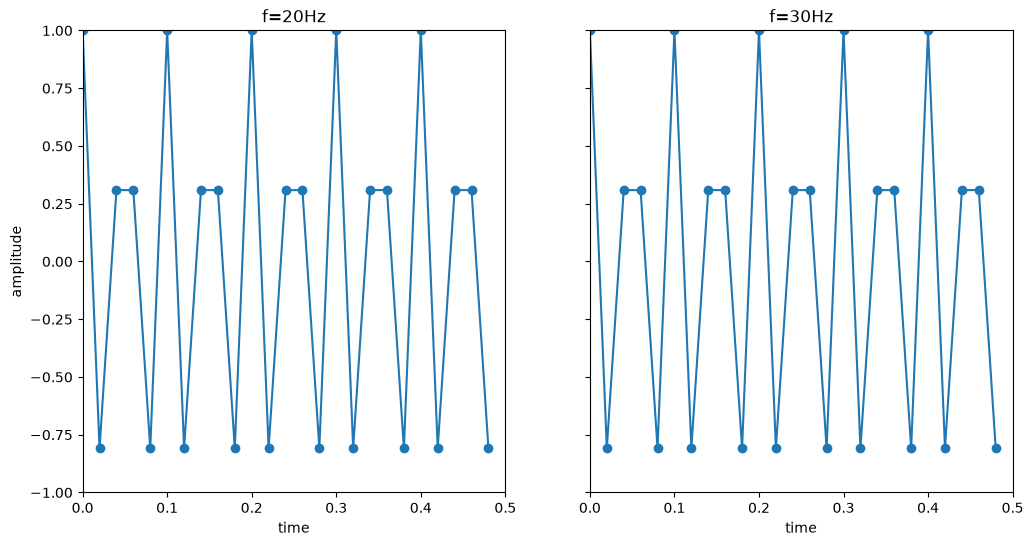

In [156]:
#Q2 plotting
A=1.0
phi=0.0
fs=50
t=0.5
n=np.arange(0,t,1/fs)

#1st case
f1=20.0
real_sinusoid_1 = gen_sine(A, f1, phi, fs, t)

#2nd case
f2=30.0
real_sinusoid_2 = gen_sine(A, f2, phi, fs, t)

fig, ax = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(12,6))

ax[0].plot(n, real_sinusoid_1, marker="o")
ax[0].set_title('f=20Hz')
ax[0].set_ylabel('amplitude')
ax[0].set_xlabel('time')

ax[1].plot(n, real_sinusoid_2, marker="o")
ax[1].set_title('f=30Hz')
ax[1].set_title('f=30Hz')
ax[1].set_xlabel('time')

#limits
ax[0].set_xlim([0, t])
ax[0].set_ylim([-A, A])

# plt.tight_layout()
plt.show()

**E2 - 1.3: Conceptual questions (answer here)**
1. Set `phi=0` and then `phi=pi/2` with the same `A`, `f`, `fs`, and `t`. How does the waveform change in time? Explain using the cosine equation.

    at phi=0 `x[0] = Acos(0) = A`
    
    while at phi=pi/2 `x[0] = Acos(pi/2) = 0`
    
    The signal is the same cosine wave but shifted in time by a quarter of period. Starting from pi/2 the sinusoid starts at 0 and goes down. The values seen in the array are closer to 0 (why all of those)?

2. Try `f=20 Hz` and `f=30 Hz` at `fs=50 Hz`. Which one violates Nyquist, and what do you observe in the plotted signal?

    Based on Nyquist to properly sample the sampling rate should be at least twice the original frequency: `fs>2*f`. Having fs=50Hz, the highest frequency we are able to properly sample is 25Hz. So, f=30Hz violates Nyquist, aliasing to 50-30=20Hz, so the plots show the same sinewaves.

## Part 2 – Generate a complex sinusoid

The function `gen_complex_sine()` should generate a complex sinusoid used by the DFT, of length `N`, at frequency index `k`.

In DFT computation we use the conjugate complex exponential, but this function should generate the base complex sinusoid itself.

Use:
- amplitude = `1`
- length = `N`
- angular frequency = `2*pi*k/N`

Inputs are positive integers `k` and `N` with `k < N`. Return `c_sine` as a NumPy array of complex values, using `np.exp()`.

In [157]:
# E2 - 2.1: Complete function gen_complex_sine()

def gen_complex_sine(k, N):
    """Generate one complex sinusoid used in DFT analysis.

    Args:
        k (int): frequency-bin index
        N (int): DFT length (number of samples)

    Returns:
        np.array: complex sinusoid of length N
    """
    ### Your code here
    assert k>=0, "Frequency-bin index must be positive"
    assert N>0, "Number of samples must be positive"
    assert k<N, "Frequency-bin index must be smaller than the number of samples"

    A=1.0
    w=2*np.pi*k/N
    n=np.arange(N)
    return A*np.exp(1j*w*n)

If you run `gen_complex_sine(k=1, N=5)`, it should return:

```
array([ 1.        +0.j        ,  0.30901699+0.95105652j,
       -0.80901699+0.58778525j, -0.80901699-0.58778525j,
        0.30901699-0.95105652j])
```

[ 1.        +0.j          0.30901699+0.95105652j -0.80901699+0.58778525j
 -0.80901699-0.58778525j  0.30901699-0.95105652j]


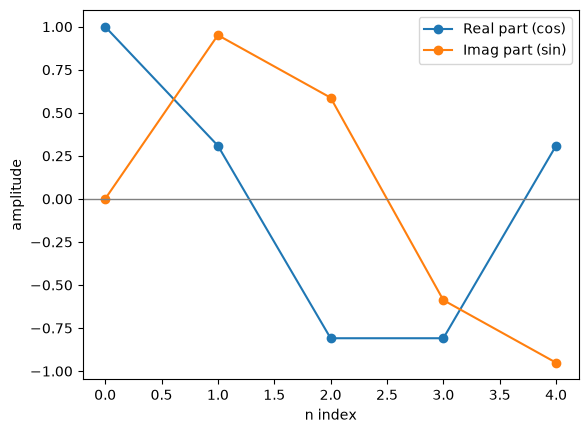

In [158]:
# E2 - 2.2: Call gen_complex_sine() with k=1 and N=5,
#            then plot real and imaginary parts of the output.

### Your code here
c_sine = gen_complex_sine(1, 5)
print(c_sine)

#ploting
n=np.arange(5)
plt.plot(n, np.real(c_sine), label="Real part (cos)", marker="o")
plt.plot(n, np.imag(c_sine), label="Imag part (sin)", marker="o")
plt.axhline(0, color="grey", linewidth=1)
plt.legend()
plt.xlabel('n index')
plt.ylabel('amplitude')
plt.show()

**E2 - 2.3: Conceptual questions (answer here)**
1. Compute (or estimate from your plot) the phase increment between consecutive samples. How does it relate to `2*pi*k/N`?

    `2*pi*k/N = 2/5*pi` in our case and that's exactly the phase increment of each sample

2. Compare `k=1` and `k=N-1` for the same `N`. What relationship do you observe between their real/imaginary parts, and why?

    They are its conjugates --> same real part, same magnitude, opposite imaginary part

## Part 3 – Implement the discrete Fourier transform (DFT)

The function `dft()` should implement the DFT equation above.

Given a sequence `x` of length `N`, return its spectrum `X` of length `N`, with frequency-bin indices from `0` to `N-1`.

In [159]:
# E2 - 3.1: Complete function dft()

def dft(x):
    """Compute the N-point DFT of a sequence.

    Args:
        x (np.array): input sequence of length N

    Returns:
        np.array: DFT spectrum of x (length N)
    """
    ### Your code here
    N=x.size
    X=np.zeros(N, dtype=complex)
    for k in range(N):
        s = gen_complex_sine(k, N)
        X[k] = np.dot(x, np.conjugate(s))

    return X

If you run `dft()` with `x = np.array([1, 2, 3, 4])`, it should return:

```
array([10.0 + 0.0j, -2.0 + 2.0j, -2.0 - 9.79717439e-16j, -2.0 - 2.0j])
```

You may not obtain exact zeros due to floating-point precision. Values around `1e-15` are numerical error and can be treated as zero.

[10.+0.00000000e+00j -2.+2.00000000e+00j -2.-9.79717439e-16j
 -2.-2.00000000e+00j]
[10.+0.j -2.+2.j -2.+0.j -2.-2.j]


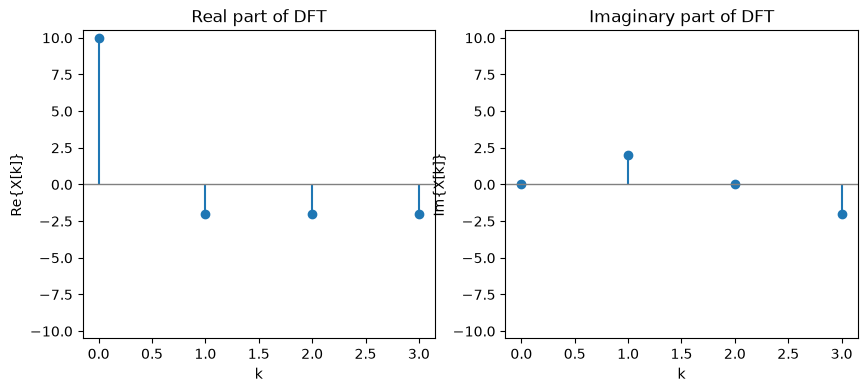

In [160]:
# E2 - 3.2: Call dft() with x = [1, 2, 3, 4],
#            then plot real and imaginary parts of the output spectrum.

### Your code here
x=np.array([1, 2, 3, 4])
spectrum=dft(x)
spectrum2=np.fft.fft(x)
print(spectrum)
print(spectrum2)

#plot
plt.figure(figsize=(10,4))
max_val=np.max(np.abs(spectrum))+0.5

plt.subplot(1, 2, 1)
plt.stem(np.arange(len(x)), np.real(spectrum), basefmt=" ")
plt.axhline(0, color="grey", linewidth=1)
plt.ylim(-max_val, max_val)
plt.title("Real part of DFT")
plt.xlabel("k")
plt.ylabel("Re{X[k]}")

plt.subplot(1, 2, 2)
plt.stem(np.arange(len(x)), np.imag(spectrum), basefmt=" ")
plt.axhline(0, color="grey", linewidth=1)
plt.ylim(-max_val, max_val)
plt.title("Imaginary part of DFT")
plt.xlabel("k")
plt.ylabel("Im{X[k]}")

plt.show()


**E2 - 3.3: Conceptual questions (answer here)**

1. In your own words, what does each DFT bin `X[k]` measure about the input signal?

    Measures how much of this frequency there is in the original signal by projecting the signal onto the exponential basis with frequency fs*k/N. The more the signal contains of this bin, the larger magnitude it will have.

2. For `x=[1,2,3,4]`, identify which bin corresponds to the DC component and verify it numerically from your output.

    The DC component is at the k=0, for `X[0]=1+2+3+4=10` so the DC bin is `X[0] = 10 + 0j` this matches the output.


3. Compare your `dft(x)` output with `np.fft.fft(x)` for one test case of your choice. Are they the same (up to numerical precision)? If not, explain where they differ.

    The outputs are the same.

## Part 4 – Implement the inverse discrete Fourier transform (IDFT)

The function `idft()` should implement the IDFT equation above.

Given a frequency spectrum `X` of length `N`, return its time-domain sequence `x` (also length `N`). Assume frequency-bin indices range from `0` to `N-1`.

Remember to apply the `1/N` scaling factor.

In [161]:
# E2 - 4.1: Complete function idft()

def idft(X):
    """Compute the N-point IDFT of a spectrum.

    Args:
        X (np.array): input spectrum of length N

    Returns:
        np.array: IDFT of X (length N)
    """
    ### Your code here
    N=X.size
    y=np.zeros(N, dtype=complex)
    for n in range(N):
        s = gen_complex_sine(n, N)
        y[n] = np.dot(X, s)/N
    return y


If you run `idft()` with `X = np.array([1, 1, 1, 1])`, the output should be close to:

```
array([ 1.00000000e+00+0.00000000e+00j, -4.59242550e-17+5.55111512e-17j,
        0.00000000e+00+6.12323400e-17j,  8.22616137e-17+8.32667268e-17j])
```

This is essentially `[1, 0, 0, 0]`, with tiny floating-point residuals. As a validation, you can compute `dft(idft(X))` and check that it returns the original `X` (up to numerical error).

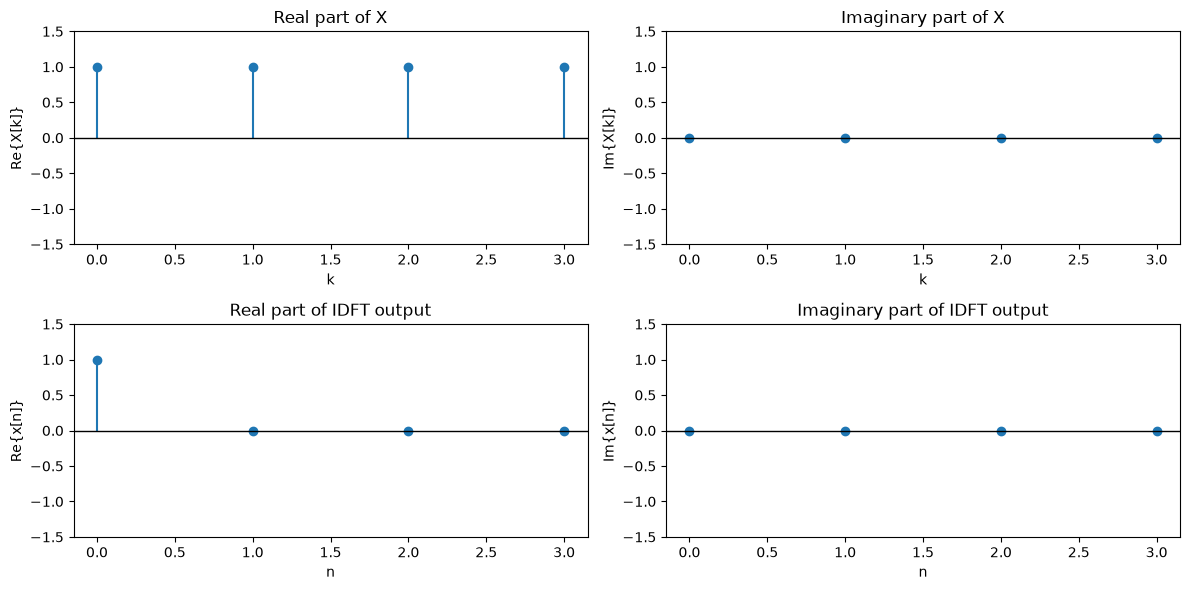

Recovered X: [1.+1.8369702e-16j 1.+6.1232340e-17j 1.-6.1232340e-17j 1.-1.8369702e-16j]
Original X: [1 1 1 1]
Max error: 1.8369701987210297e-16


In [162]:
# E2 - 4.2: Plot real/imaginary parts of X = [1, 1, 1, 1], call idft(),
#            plot real/imaginary parts of the output sequence,
#            then compute dft() of that output to validate reconstruction.

### Your code here
X = np.array([1, 1, 1, 1])
signal = idft(X)
signal

#plot
plt.figure(figsize=(12, 6))

plt.subplot(2, 2, 1)
plt.stem(np.arange(len(X)), np.real(X), basefmt=" ")
plt.axhline(0, color="black", linewidth=1)
plt.ylim(-1.5, 1.5)
plt.title("Real part of X")
plt.xlabel("k")
plt.ylabel("Re{X[k]}")

plt.subplot(2, 2, 2)
plt.stem(np.arange(len(X)), np.imag(X), basefmt=" ")
plt.axhline(0, color="black", linewidth=1)
plt.ylim(-1.5, 1.5)
plt.title("Imaginary part of X")
plt.xlabel("k")
plt.ylabel("Im{X[k]}")

# Plot IDFT output
plt.subplot(2, 2, 3)
plt.stem(np.arange(len(signal)), np.real(signal), basefmt=" ")
plt.axhline(0, color="black", linewidth=1)
plt.ylim(-1.5, 1.5)
plt.title("Real part of IDFT output")
plt.xlabel("n")
plt.ylabel("Re{x[n]}")

plt.subplot(2, 2, 4)
plt.stem(np.arange(len(signal)), np.imag(signal), basefmt=" ")
plt.axhline(0, color="black", linewidth=1)
plt.ylim(-1.5, 1.5)
plt.title("Imaginary part of IDFT output")
plt.xlabel("n")
plt.ylabel("Im{x[n]}")

plt.tight_layout()
plt.show()


# Validate reconstruction
X_recovered = dft(signal)
print("Recovered X:", X_recovered)
print("Original X:", X)
print("Max error:", np.max(np.abs(X_recovered - X)))

In [163]:
x2=np.array([1,0,-1,0])
x_hat=idft(dft(x2))
print("Max error:", np.max(np.abs(x_hat - x2)))

Max error: 1.3691967456605072e-16


**E2 - 4.3: Conceptual questions (answer here)**

1. Why does the IDFT include the factor `1/N` while the DFT (as implemented here) does not?
    
    As after the IDFT we want to obtain the original signal, this step must normalize. The normalized value after DFT is not so important after that step.

2. Use one example where you compute `x_hat = idft(dft(x))`. How close is `x_hat` to `x`? Report the maximum absolute error.
    
    Max error: 1.3691967456605072e-16

3. Your IDFT output may contain tiny imaginary residuals for real signals. Why do these appear, and when is it safe to discard them with `np.real(...)`?
    
    Because of floating-points, they are numerical artifacts, not factual signal content and it is safe to use np.real on them if they are really small compared to the real part of the signal.

## Part 5 – Compute the magnitude spectrum

The function `gen_mag_spec()` should compute the magnitude spectrum of an input sequence `x` of length `N`.

Return an `N`-point magnitude spectrum with frequency-bin indices from `0` to `N-1`.

In [164]:
# E2 - 5.1: Complete function gen_mag_spec()

def gen_mag_spec(x):
    """Compute magnitude spectrum of a sequence.

    Args:
        x (np.array): input sequence of length N

    Returns:
        np.array: magnitude spectrum of x (length N)
    """
    ### Your code here
    X=dft(x)
    return np.abs(X)

If you run `gen_mag_spec()` with `x = np.array([1, 2, 3, 4])`, it should return:

```
array([10.0, 2.82842712, 2.0, 2.82842712])
```

For a more realistic case, use a longer input such as:

`x = np.cos(2*np.pi*200.0*np.arange(512)/1000)`

Then plot both input and output using `plt.plot(x)` and `plt.plot(X)`.

Peak magnitude index: k = 102
Estimated peak frequency: 199.22 Hz
Expected sinusoid frequency: 200.0 Hz


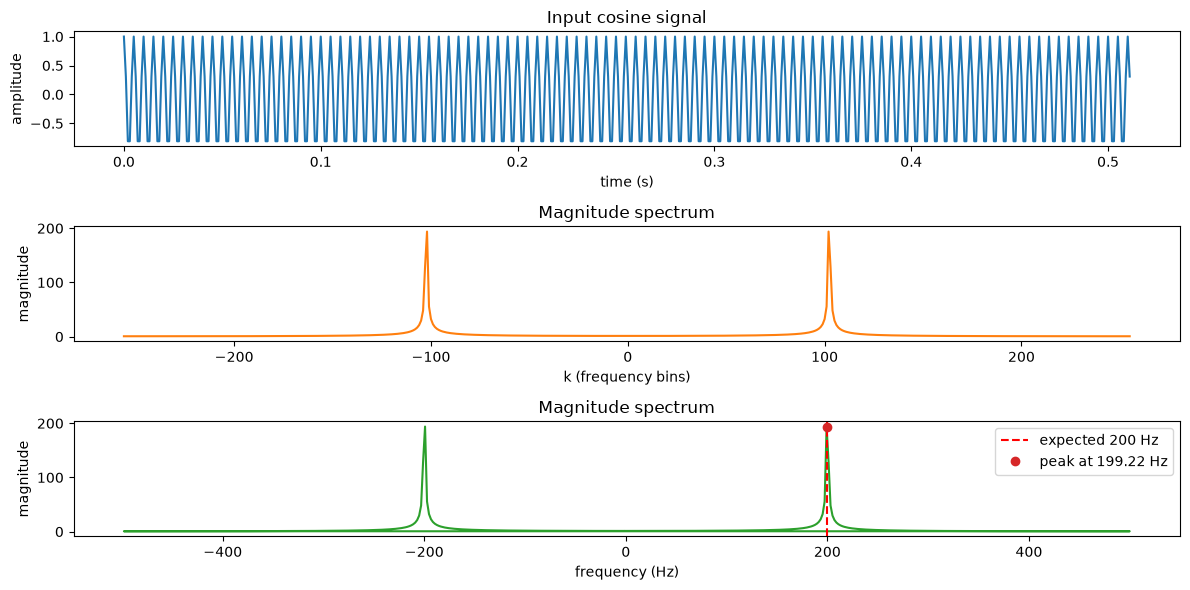

In [165]:
# E2 - 5.2: Plot the input cosine signal, call gen_mag_spec(), and plot the output magnitude spectrum.
#            Validate that the spectral peak matches the sinusoid frequency.

### Your code here
fs = 1000.0
x1 = np.array([1, 2, 3, 4])
x2 = np.cos(2 * np.pi * 200.0 * np.arange(512) / fs)

mags1 = gen_mag_spec(x1)
mags2 = gen_mag_spec(x2)

# Frequency axis for the spectrum
N=len(x2)
freqs = np.arange(N)*fs / N
freqs[freqs > fs/2] -= fs

# Peak in the positive-frequency side of the DFT

k_peak = np.argmax(mags2[:N//2])
peak_freq = freqs[k_peak]

print(f"Peak magnitude index: k = {k_peak}")
print(f"Estimated peak frequency: {peak_freq:.2f} Hz")
print(f"Expected sinusoid frequency: 200.0 Hz")

#Ploy
fig, ax = plt.subplots(3, 1, figsize=(12, 6))

ax[0].plot(np.arange(N) / fs, x2, color="C0")
ax[0].set_title("Input cosine signal")
ax[0].set_xlabel("time (s)")
ax[0].set_ylabel("amplitude")
mags2_shifted = np.concatenate((mags2[N//2:], mags2[:N//2]))
ax[1].plot(np.arange(-N//2, N//2), mags2_shifted, color="C1")
ax[1].set_title("Magnitude spectrum")
ax[1].set_xlabel("k (frequency bins)")
ax[1].set_ylabel("magnitude")

ax[2].plot(freqs, mags2, color="C2")
ax[2].axvline(200, color="r", linestyle="--", label="expected 200 Hz")
ax[2].plot(peak_freq, mags2[k_peak], "o", color="C3", label=f"peak at {peak_freq:.2f} Hz")
ax[2].set_title("Magnitude spectrum")
ax[2].set_xlabel("frequency (Hz)")
ax[2].set_ylabel("magnitude")
ax[2].legend()

plt.tight_layout()
plt.show()


**E2 - 5.3: Conceptual questions (answer here)**

1. From your magnitude spectrum plot, report the bin index of the main peak and convert it to frequency in Hz. Compare with the sinusoid frequency used to generate the signal.

    The bin index of the main peak is 102. Using fs=1000 and N=512 we get 
    `f_k = 102*1000/512 = 199.22 Hz` For generating the signal we used f=200Hz.

2. Explain why the spectrum of a real cosine shows two symmetric peaks (positive and negative frequency bins in the DFT indexing).

    Because the resulting spectrum is symmetric, its a property of the real signal dft. Explain more

3. Change the sinusoid amplitude from `1.0` to `0.5` (keeping everything else fixed). How does the magnitude spectrum change? Quantify the change in peak magnitude.

    The magnitude peak is 1/2 of the original peak (200 -> 100), so it scales proportionally to the amplitude.

4. If the sinusoid frequency is not exactly at a DFT bin center, what effect do you observe in the spectrum? Describe it and explain why it happens.

    We observe spectral leakage, meaning that all other bins have positive values even if they are not present in the original signal, why it happens?

In [166]:
listt=[1,2,3,4,5,6]
N=len(listt)
ar=np.concatenate((listt[N//2:], listt[:N//2]))
ar

array([4, 5, 6, 1, 2, 3])